<a href="https://colab.research.google.com/github/gustavojaymebuso-collab/calculo_numerico/blob/main/Tarefa_Interpolacao.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tarefa investigativa: erros em métodos de interpolação

### Aplicação: reconstrução da temperatura em uma barra aquecida

Uma barra homogênea de comprimento $L=6$ m está sujeita a temperaturas prescritas nas extremidades e recebe calor de uma fonte distribuída em seu interior. Sensores medem a temperatura em posições discretas. A equipe precisa estimar a temperatura em posições onde não há sensor e avaliar a incerteza dessas estimativas.

Esta atividade combina um modelo simplificado de transferência de calor com interpolação numérica. O objetivo não é resolver a equação diferencial de calor por diferenças finitas. O perfil analítico será usado como referência, para que os erros de diferentes métodos de interpolação possam ser medidos e comparados.

Você vai comparar **polinômio global de Lagrange** e uma **spline cúbica**, primeiro com dados exatos e depois com medições perturbadas por ruído.


## 1. Problema físico e equação de transferência de calor

### 1.1 Modelo físico

Considere uma barra sólida homogênea, com comprimento $L=6$ m e seção transversal constante. A temperatura varia principalmente ao longo do eixo $x$. As extremidades são mantidas a temperaturas conhecidas. No interior, uma fonte térmica volumétrica distribui energia ao longo da barra.

A equação geral de energia térmica, para propriedades constantes e sem mudança de fase, pode ser escrita como

$$\rho c_p\frac{\partial T}{\partial t}=k\nabla^2T+\dot q^{\prime\prime\prime}-\rho c_p\,\mathbf{u}\cdot\nabla T,$$

em que $T$ é a temperatura (K ou °C para diferenças), $t$ é o tempo (s), $\rho$ é a massa específica (kg m$^{-3}$), $c_p$ é o calor específico (J kg$^{-1}$ K$^{-1}$), $k$ é a condutividade térmica (W m$^{-1}$ K$^{-1}$), $\dot q^{\prime\prime\prime}$ é a geração volumétrica de calor (W m$^{-3}$) e $\mathbf{u}$ representa o movimento de um fluido, quando há advecção.

Para esta atividade, adotamos uma **barra sólida em regime estacionário**, sem escoamento interno, com condução unidimensional e geração de calor. Assim, $\partial T/\partial t=0$, $\mathbf{u}=0$ e $\nabla^2T=d^2T/dx^2$. A equação fica

$$k\frac{d^2T}{dx^2}+\dot q^{\prime\prime\prime}(x)=0,\qquad 0<x<L,$$

com condições de contorno de Dirichlet

$$T(0)=18\ ^\circ\mathrm C,\qquad T(L)=20.4\ ^\circ\mathrm C.$$

O primeiro termo representa a condução: diferenças espaciais de temperatura geram fluxo de calor. O termo $\dot q^{\prime\prime\prime}(x)$ representa energia adicionada por unidade de volume e de tempo. O sinal positivo de $\dot q^{\prime\prime\prime}$ indica geração interna de calor.

### 1.2 Perfil de referência usado no experimento

Para criar um caso com solução conhecida, definimos $\xi=x/L$ e adotamos

$$T(x)=18+2.4\,\xi+2.5\sin(\pi\xi),\qquad \xi=\frac{x}{L},\quad 0\le x\le L.$$

A parcela linear garante as temperaturas prescritas nas extremidades. A parcela senoidal representa um aquecimento distribuído mais intenso no interior e nulo nas bordas. Derivando duas vezes em relação à coordenada física $x$,

$$\frac{d^2T}{dx^2}=-\frac{2.5\pi^2}{L^2}\sin\left(\frac{\pi x}{L}\right).$$

Portanto, esse perfil satisfaz a equação estacionária se a geração volumétrica for

$$\dot q^{\prime\prime\prime}(x)=\frac{2.5\,k\pi^2}{L^2}\sin\left(\frac{\pi x}{L}\right).$$

Como $\sin(\pi x/L)\ge0$ dentro da barra, a fonte é não negativa. Não precisamos escolher um valor numérico para $k$: o objetivo é verificar a coerência do perfil e estudar a interpolação. A função analítica é uma referência idealizada; em uma aplicação experimental, seria preciso estimar propriedades, fontes, perdas e condições de contorno.

### 1.3 Questão investigativa

**Como a resposta depende da quantidade e posição dos sensores e do ruído de medição?**



### O que significa erro de interpolação?

Em um ponto de avaliação $x$, o erro assinado é $e(x)=p(x)-T(x)$. O erro absoluto é $|e(x)|$. Como a interpolação reproduz os nós, o erro nesses pontos pode ser praticamente zero; por isso, avaliaremos também muitos pontos **entre** os nós.

Usaremos: erro máximo absoluto $E_{max}=\max_j|e_j|$; erro médio absoluto (MAE) $=\frac{1}{m}\sum_j|e_j|$; raiz do erro quadrático médio (RMSE) $=\sqrt{\frac{1}{m}\sum_j e_j^2}$. O RMSE penaliza mais erros grandes.

## 2. Figura do problema e preparação do ambiente

A figura esquematiza a barra, os sensores, as temperaturas nas extremidades e a fonte térmica interna. A curva corresponde ao perfil de referência usado no experimento. Os pontos são as posições onde os sensores amostram a temperatura.

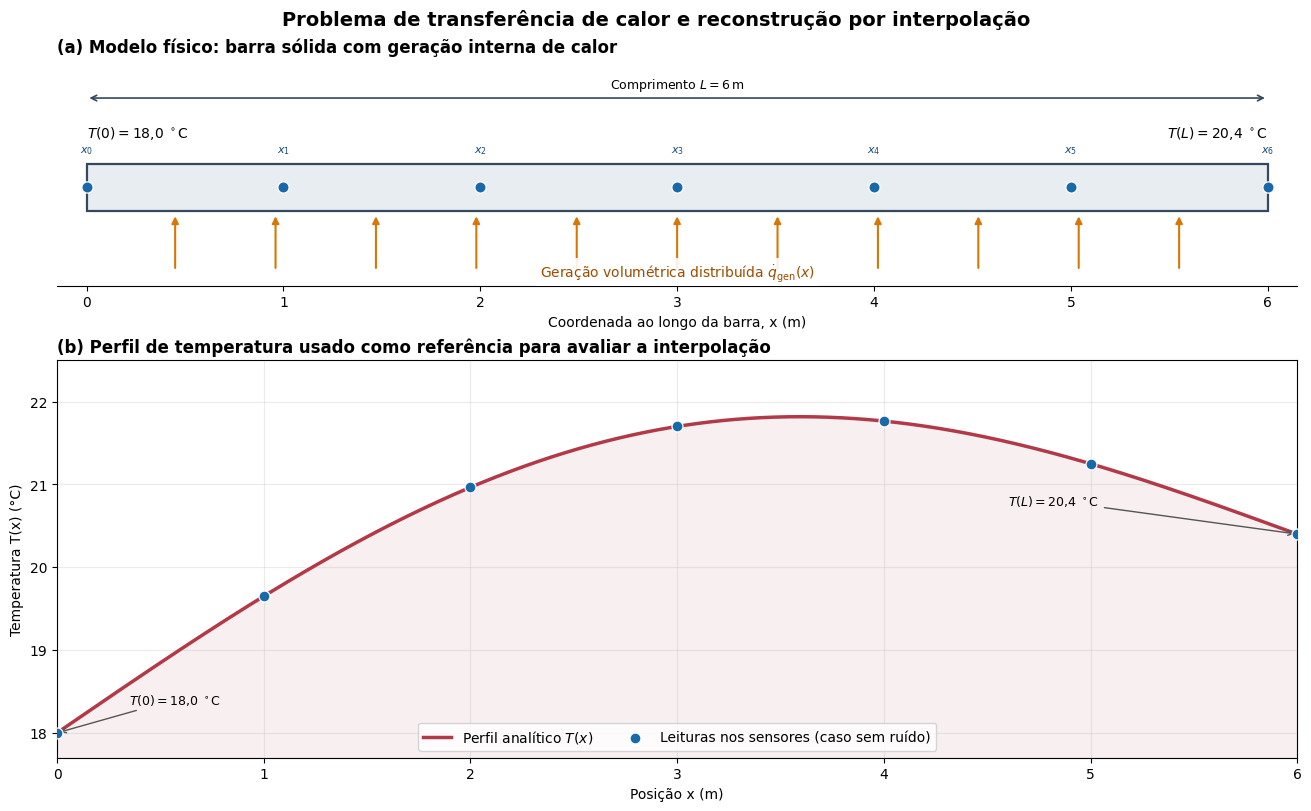

Temperaturas nas extremidades: T(0)=18.0 °C e T(L)=20.4 °C


In [ ]:
# Preparação do modelo e bibliotecas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import BarycentricInterpolator, interp1d, CubicSpline
from matplotlib.patches import Rectangle

np.set_printoptions(precision=4, suppress=True)
plt.rcParams["figure.figsize"] = (9, 5)
L = 6.0  # comprimento da barra, m

def temperatura_real(x):
    """Perfil analítico de referência em °C; x é dado em metros."""
    x = np.asarray(x, dtype=float)
    xi = x/L
    return 18 + 2.4*xi + 2.5*np.sin(np.pi*xi)

x_min, x_max = 0.0, L
x_fino = np.linspace(x_min, x_max, 2001)
T_fino = temperatura_real(x_fino)

# Figura do problema: esquema físico e perfil analítico em painéis separados

x_sensores_fig = np.linspace(0, L, 7)
T_sensores_fig = temperatura_real(x_sensores_fig)

fig = plt.figure(figsize=(13, 8), constrained_layout=True)
gs = fig.add_gridspec(2, 1, height_ratios=[0.85, 1.5])
ax_esq = fig.add_subplot(gs[0])
ax_perfil = fig.add_subplot(gs[1])

# Painel (a): barra física, sensores e fonte interna distribuída
ax_esq.set_title("(a) Modelo físico: barra sólida com geração interna de calor", loc="left", fontsize=12, weight="bold")
barra_y, barra_h = 0.40, 0.25
ax_esq.add_patch(Rectangle((0, barra_y), L, barra_h, facecolor="#e8edf2",
                           edgecolor="#34495e", linewidth=1.6, zorder=1))
# Sensores ao longo do eixo da barra
ax_esq.scatter(x_sensores_fig, np.full_like(x_sensores_fig, barra_y+barra_h/2),
               s=65, marker="o", facecolor="#1769aa", edgecolor="white", linewidth=0.9,
               zorder=4, label="Sensores")
# Aquecimento interno: setas iguais identificam geração distribuída, sem sugerir fluxo de calor externo
for xpos in np.linspace(0.45, 5.55, 11):
    ax_esq.annotate("", xy=(xpos, barra_y-0.015), xytext=(xpos, 0.08),
                    arrowprops={"arrowstyle":"-|>", "color":"#d97706", "lw":1.5}, zorder=3)
ax_esq.text(L/2, 0.015, r"Geração volumétrica distribuída $\dot{q}_{\mathrm{gen}}(x)$",
            ha="center", va="bottom", color="#9a4d00", fontsize=10,
            bbox={"facecolor":"white", "edgecolor":"none", "alpha":0.88, "pad":2.5})
ax_esq.text(0, 0.77, r"$T(0)=18{,}0\ ^\circ\mathrm{C}$", ha="left", va="bottom", fontsize=10)
ax_esq.text(L, 0.77, r"$T(L)=20{,}4\ ^\circ\mathrm{C}$", ha="right", va="bottom", fontsize=10)
# Linha de dimensão e eixo longitudinal
ax_esq.annotate("", xy=(L, 1.00), xytext=(0, 1.00),
                arrowprops={"arrowstyle":"<->", "color":"#34495e", "lw":1.2})
ax_esq.text(L/2, 1.025, r"Comprimento $L=6\,\mathrm{m}$", ha="center", va="bottom", fontsize=9)
for i, xpos in enumerate(x_sensores_fig):
    ax_esq.text(xpos, barra_y+barra_h+0.04, rf"$x_{i}$", ha="center", va="bottom", fontsize=8, color="#174a73")
ax_esq.set_xlim(-0.15, L+0.15); ax_esq.set_ylim(0, 1.2)
ax_esq.set_xlabel("Coordenada ao longo da barra, x (m)")
ax_esq.set_yticks([]); ax_esq.grid(False)
for spine in ["left", "right", "top"]: ax_esq.spines[spine].set_visible(False)

# Painel (b): curva de referência e posições amostradas
ax_perfil.set_title("(b) Perfil de temperatura usado como referência para avaliar a interpolação",
                    loc="left", fontsize=12, weight="bold")
ax_perfil.plot(x_fino, T_fino, color="#b23a48", linewidth=2.5,
               label=r"Perfil analítico $T(x)$", zorder=2)
ax_perfil.scatter(x_sensores_fig, T_sensores_fig, s=62, marker="o",
                  facecolor="#1769aa", edgecolor="white", linewidth=0.9,
                  label="Leituras nos sensores (caso sem ruído)", zorder=4)
ax_perfil.fill_between(x_fino, T_fino, np.min(T_fino)-0.3,
                       color="#b23a48", alpha=0.08, zorder=1)
ax_perfil.annotate(r"$T(0)=18{,}0\ ^\circ\mathrm{C}$",
                   xy=(0, temperatura_real(0)), xytext=(0.35, 18.35),
                   arrowprops={"arrowstyle":"->", "color":"#555"}, fontsize=9)
ax_perfil.annotate(r"$T(L)=20{,}4\ ^\circ\mathrm{C}$",
                   xy=(L, temperatura_real(L)), xytext=(4.6, 20.75),
                   arrowprops={"arrowstyle":"->", "color":"#555"}, fontsize=9)
ax_perfil.set_xlim(0, L); ax_perfil.set_ylim(17.7, 22.5)
ax_perfil.set_xlabel("Posição x (m)")
ax_perfil.set_ylabel("Temperatura T(x) (°C)")
ax_perfil.grid(True, alpha=0.25); ax_perfil.legend(loc="lower center", ncol=2, frameon=True)
fig.suptitle("Problema de transferência de calor e reconstrução por interpolação", fontsize=14, weight="bold")
plt.show()

print(f"Temperaturas nas extremidades: T(0)={temperatura_real(0):.1f} °C e T(L)={temperatura_real(L):.1f} °C")

### Implementação das splines e dos métodos de interpolação

In [ ]:
def spline_quadratica_coef(x, y):
    """Spline quadrática C1 com condição c_0=0; retorna a,b,c locais."""
    x = np.asarray(x, float); y = np.asarray(y, float)
    n = len(x)-1
    if n < 1 or len(y) != len(x) or np.any(np.diff(x) <= 0):
        raise ValueError("x deve ser crescente e ter o mesmo tamanho de y.")
    A = np.zeros((3*n, 3*n)); rhs = np.zeros(3*n); row = 0
    # S_i(x_i)=y_i
    for i in range(n):
        A[row, i] = 1; rhs[row] = y[i]; row += 1
    # S_i(x_(i+1))=y_(i+1)
    for i in range(n):
        h = x[i+1]-x[i]
        A[row, i] = 1; A[row, n+i] = h; A[row, 2*n+i] = h*h
        rhs[row] = y[i+1]; row += 1
    # Continuidade da primeira derivada nos nós internos
    for i in range(n-1):
        h = x[i+1]-x[i]
        A[row, n+i] = 1; A[row, 2*n+i] = 2*h; A[row, n+i+1] = -1
        row += 1
    # Condição de contorno: c_0=0
    A[row, 2*n] = 1
    coef = np.linalg.solve(A, rhs)
    return coef[:n], coef[n:2*n], coef[2*n:]

def spline_quadratica_avalia(x, coef, xq):
    a, b, c = coef
    xq = np.asarray(xq, dtype=float)
    idx = np.clip(np.searchsorted(x, xq, side="right")-1, 0, len(a)-1)
    t = xq-x[idx]
    return a[idx] + b[idx]*t + c[idx]*t**2

def criar_metodos(x, y):
    """Retorna dicionário: interpoladores callable para quatro métodos."""
    lagrange = BarycentricInterpolator(x, y)
    linear = interp1d(x, y, kind="linear", bounds_error=True)
    quad_coef = spline_quadratica_coef(x, y)
    quad = lambda z: spline_quadratica_avalia(x, quad_coef, z)
    cubica = CubicSpline(x, y, bc_type="natural")
    return {"Lagrange global": lagrange,
            "Spline linear": linear,
            "Spline quadrática": quad,
            "Spline cúbica natural": cubica}

def calcular_metricas(metodos, x_teste, y_verdadeiro):
    linhas = []
    for nome, metodo in metodos.items():
        erro = np.asarray(metodo(x_teste))-np.asarray(y_verdadeiro)
        linhas.append({"Método": nome,
                       "Erro máximo (°C)": np.max(np.abs(erro)),
                       "MAE (°C)": np.mean(np.abs(erro)),
                       "RMSE (°C)": np.sqrt(np.mean(erro**2))})
    return pd.DataFrame(linhas).sort_values("RMSE (°C)").reset_index(drop=True)

print("Funções de interpolação e métricas definidas.")

Funções de interpolação e métricas definidas.


## 3. Métodos de interpolação e métricas de erro

O interpolador global de Lagrange passa por todos os sensores usando um único polinômio. Usamos a forma baricêntrica, que evita expandir diretamente os coeficientes e costuma ser numericamente mais estável.

As splines constroem polinômios por intervalos. A spline linear conecta pontos por retas. A quadrática deste notebook impõe continuidade da função e da primeira derivada e usa a condição de contorno $c_0=0$ no primeiro intervalo. A spline cúbica natural impõe continuidade até a segunda derivada e segunda derivada nula nas extremidades.

Para quantificar a diferença, calculamos $e(x)=T_{interp}(x)-T_{ref}(x)$. O erro máximo mostra o pior desvio na malha. O MAE dá o desvio absoluto médio. O RMSE penaliza mais os erros de grande magnitude. Todos têm unidade de graus Celsius.

A malha fina serve como conjunto de pontos de avaliação: os valores nela não são novos sensores. Assim, a comparação mede desempenho entre os nós.

**Nota de implementação.** As funções `criar_metodos` e `calcular_metricas` foram definidas na célula anterior e serão reutilizadas nas próximas etapas. A cópia duplicada dessas definições, presente no notebook original, foi retirada para evitar redundância.

## Etapa 1 — Interpolação com dados exatos
Suponha primeiro que os sensores sejam perfeitos. Coloque sete sensores em posições igualmente espaçadas, incluindo as duas extremidades. Os valores registrados são então exatamente $T(x_i)$.

### Passo a passo
1. Construa o vetor das posições e avalie o perfil de referência nesses pontos.
2. Crie a interpolação com `criar_metodos`.
3. Avalie cada método em `x_fino`, uma malha densa entre 0 e 6 m.
4. Calcule $E_{max}$, MAE e RMSE comparando cada curva com `T_fino`.
5. Faça um gráfico das temperaturas e outro dos erros assinados.




Etapa 1 — métricas de erro (dados exatos):


,Método,Erro máximo (°C),MAE (°C),RMSE (°C)
0,Lagrange global,8.468221e-05,1.917900e-05,3.270695e-05
1,Spline cúbica natural,5.060068e-04,1.841431e-04,2.391482e-04
2,Spline quadrática,2.392716e-02,1.495017e-02,1.646552e-02
3,Spline linear,8.229382e-02,3.650998e-02,4.396661e-02


Verificação: os quatro interpoladores reproduzem os sete nós.


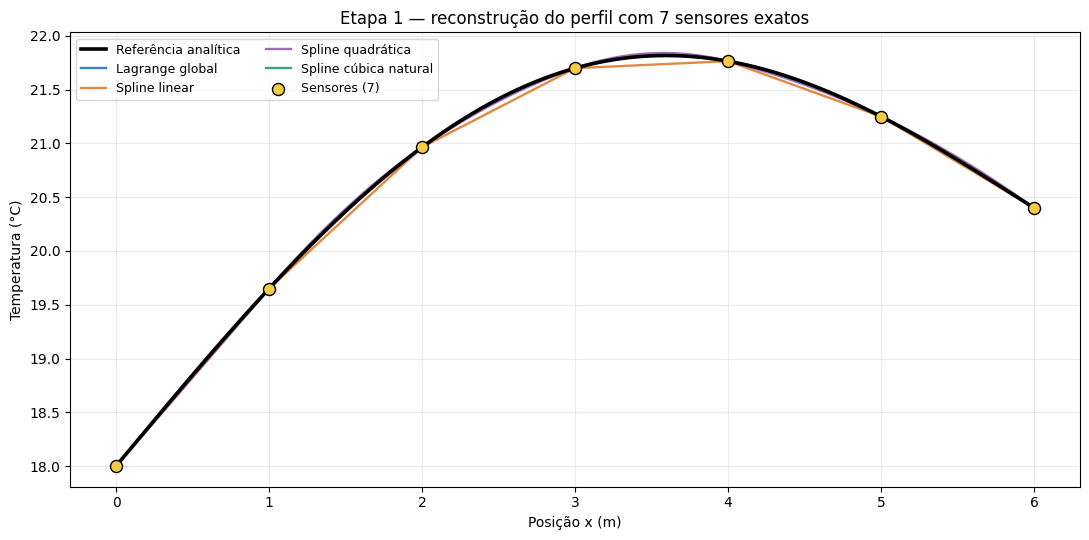

In [ ]:
# Etapa 1 — Sete sensores equidistantes com leituras exatas
x_nos_7 = np.linspace(x_min, x_max, 7)
y_nos_7 = temperatura_real(x_nos_7)
metodos_7 = criar_metodos(x_nos_7, y_nos_7)

# Métricas calculadas em 2.001 posições (incluindo os intervalos entre sensores)
metricas_7 = calcular_metricas(metodos_7, x_fino, T_fino)
print('Etapa 1 — métricas de erro (dados exatos):')
display(metricas_7.style.format({
    'Erro máximo (°C)': '{:.6e}',
    'MAE (°C)': '{:.6e}',
    'RMSE (°C)': '{:.6e}'
}))

# Verificação de que todos os métodos reproduzem as leituras nos nós
for nome, metodo in metodos_7.items():
    assert np.allclose(metodo(x_nos_7), y_nos_7, atol=1e-10), nome
print('Verificação: os quatro interpoladores reproduzem os sete nós.')

# Comparação dos perfis de temperatura
cores = {'Lagrange global': '#1377b7', 'Spline linear': '#dc7826',
         'Spline quadrática': '#8c57aa', 'Spline cúbica natural': '#1e986f'}
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.plot(x_fino, T_fino, color='black', lw=2.6, label='Referência analítica', zorder=5)
for nome, metodo in metodos_7.items():
    ax.plot(x_fino, metodo(x_fino), lw=1.7, alpha=0.87,
            label=nome, color=cores[nome])
ax.scatter(x_nos_7, y_nos_7, s=75, marker='o', color='#f5cb45',
           edgecolors='black', zorder=7, label='Sensores (7)')
ax.set(xlabel='Posição x (m)', ylabel='Temperatura (°C)',
       title='Etapa 1 — reconstrução do perfil com 7 sensores exatos')
ax.grid(alpha=.25)
ax.legend(ncol=2, fontsize=9)
plt.tight_layout()
plt.show()

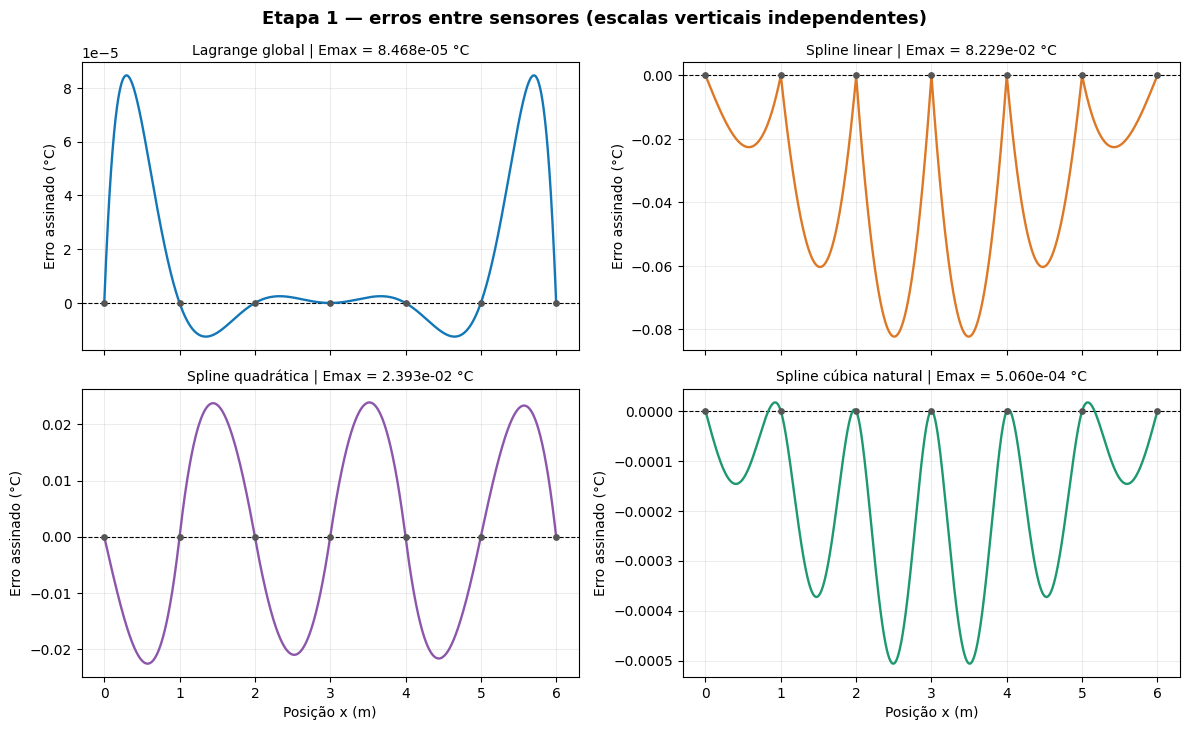

In [ ]:
# Gráficos individuais do erro assinado: e(x) = interpolação - referência
# Cada painel usa sua própria escala vertical para revelar o formato do erro.
fig, eixos = plt.subplots(2, 2, figsize=(12, 7.4), sharex=True)
for ax, (nome, metodo) in zip(eixos.flat, metodos_7.items()):
    erro = np.asarray(metodo(x_fino)) - T_fino
    ax.axhline(0, color='black', ls='--', lw=.8)
    ax.plot(x_fino, erro, color=cores[nome], lw=1.7)
    ax.scatter(x_nos_7, np.zeros_like(x_nos_7), color='#555', s=15, zorder=3)
    ax.set_title(f'{nome} | Emax = {np.max(np.abs(erro)):.3e} °C', fontsize=10)
    ax.set_ylabel('Erro assinado (°C)')
    ax.grid(alpha=.23)
for ax in eixos[-1, :]:
    ax.set_xlabel('Posição x (m)')
fig.suptitle('Etapa 1 — erros entre sensores (escalas verticais independentes)',
             fontsize=13, weight='bold')
plt.tight_layout()
plt.show()

### Análise da Etapa 1

Com sete sensores e dados **exatos**, o método de **Lagrange global** apresenta o menor erro: $E_{max}\approx 8{,}47\times10^{-5}$ °C e RMSE $\approx 3{,}27\times10^{-5}$ °C. A **spline cúbica natural** vem em seguida ($E_{max}\approx 5{,}06\times10^{-4}$ °C; RMSE $\approx 2{,}39\times10^{-4}$ °C). Já a spline quadrática tem RMSE de aproximadamente $1{,}65\times10^{-2}$ °C, e a spline linear, de $4{,}40\times10^{-2}$ °C.

Os métodos reproduzem as temperaturas exatamente nas posições amostradas, mas isso não implica erro nulo *entre* sensores. A interpolação linear não acompanha perfeitamente a curvatura do perfil; a quadrática também depende da condição escolhida no primeiro intervalo ($c_0=0$). Para este perfil suave, Lagrange aproxima muito bem a parcela senoidal com apenas sete nós. Esse resultado vale para os **dados exatos e este perfil**, não é uma garantia para qualquer curva ou medição com ruído. Os painéis de erro usam escalas diferentes, portanto os valores numéricos são indispensáveis para comparar os métodos.

## Etapa 2 — Número e posição dos sensores

Nesta etapa, investigue somente o polinômio global de Lagrange. A interpolação polinomial global pode oscilar entre nós, sobretudo perto das extremidades, quando se usam muitos nós equiespaçados. A distribuição de Chebyshev concentra nós nas bordas e pode reduzir esse efeito.

Para $N$ nós de Chebyshev-Lobatto em $[a,b]$, use

$$x_k=\frac{a+b}{2}+\frac{b-a}{2}\cos\left(\frac{k\pi}{N-1}\right),\quad k=0,\ldots,N-1.$$

Ordene as posições crescentemente. Compare $N=5,9,13,17$ para nós equiespaçados e de Chebyshev. Para cada caso, avalie o erro em todos os pontos da malha fina e registre o erro máximo e o RMSE.

**Atenção:** uma redução de erro neste perfil particular não prova que o mesmo ocorrerá para qualquer função. Relacione a observação à suavidade e à estrutura do perfil usado.

Etapa 2 — efeito da posição e da quantidade de sensores:


,N,Distribuição,Erro máximo (°C),RMSE (°C)
0,5,Chebyshev–Lobatto,2.326599e-03,1.532697e-03
1,5,Equidistantes,4.530257e-03,2.159567e-03
2,9,Chebyshev–Lobatto,2.167582e-07,1.202332e-07
3,9,Equidistantes,1.043537e-06,3.438146e-07
4,13,Chebyshev–Lobatto,3.627321e-12,1.932031e-12
5,13,Equidistantes,5.914913e-11,1.545140e-11
6,17,Chebyshev–Lobatto,1.421085e-14,3.935962e-15
7,17,Equidistantes,1.989520e-12,2.445428e-13


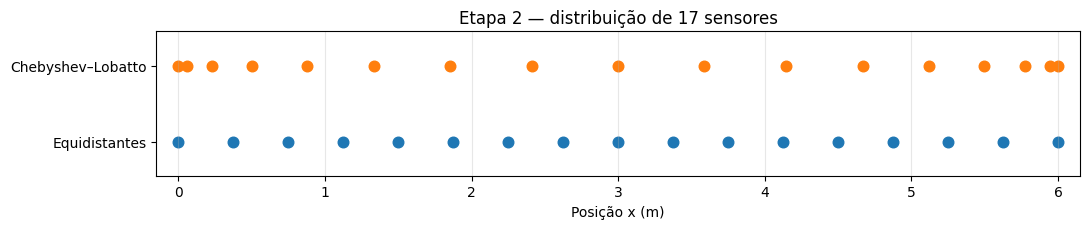

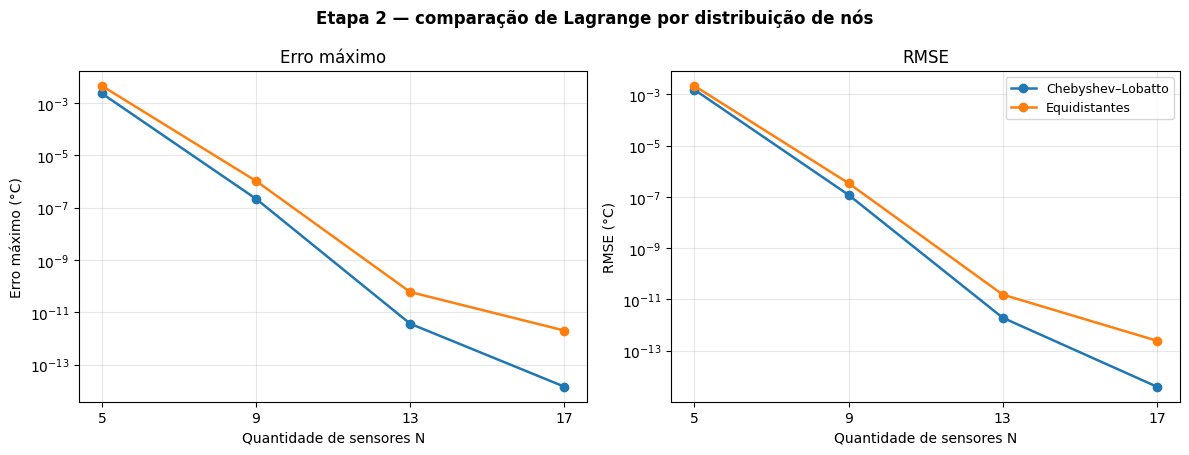

In [ ]:
def nos_chebyshev_lobatto(a, b, N):
    """N nós de Chebyshev–Lobatto em [a,b], em ordem crescente."""
    if N < 2:
        raise ValueError('São necessários pelo menos dois nós.')
    k = np.arange(N)
    z = np.cos(k*np.pi/(N-1))
    return np.sort((a+b)/2 + (b-a)*z/2)

# Lagrange com nós equidistantes versus nós de Chebyshev–Lobatto.
linhas_nos = []
for N in [5, 9, 13, 17]:
    casos = {
        'Equidistantes': np.linspace(x_min, x_max, N),
        'Chebyshev–Lobatto': nos_chebyshev_lobatto(x_min, x_max, N)
    }
    for distribuicao, x_nos in casos.items():
        y_nos = temperatura_real(x_nos)
        polinomio = BarycentricInterpolator(x_nos, y_nos)
        erro = np.asarray(polinomio(x_fino)) - T_fino
        linhas_nos.append({
            'N': N, 'Distribuição': distribuicao,
            'Erro máximo (°C)': np.max(np.abs(erro)),
            'RMSE (°C)': np.sqrt(np.mean(erro**2))
        })

tabela_nos = pd.DataFrame(linhas_nos).sort_values(['N', 'Distribuição']).reset_index(drop=True)
print('Etapa 2 — efeito da posição e da quantidade de sensores:')
display(tabela_nos.style.format({
    'Erro máximo (°C)': '{:.6e}', 'RMSE (°C)': '{:.6e}'
}))

# Visualização da distribuição espacial para N = 17
fig, ax = plt.subplots(figsize=(11, 2.4))
for altura, distribuicao in [(0, 'Equidistantes'), (1, 'Chebyshev–Lobatto')]:
    x_nos = (np.linspace(0, L, 17) if altura == 0
             else nos_chebyshev_lobatto(0, L, 17))
    ax.scatter(x_nos, np.full(17, altura), s=58, label=distribuicao)
ax.set(xlim=(-.15, L+.15), ylim=(-.45, 1.45),
       xlabel='Posição x (m)', title='Etapa 2 — distribuição de 17 sensores')
ax.set_yticks([0, 1], ['Equidistantes', 'Chebyshev–Lobatto'])
ax.grid(axis='x', alpha=.3)
plt.tight_layout()
plt.show()

# Comparação das métricas por quantidade de sensores
fig, eixos = plt.subplots(1, 2, figsize=(12, 4.6))
for distribuicao, g in tabela_nos.groupby('Distribuição'):
    for ax, metrica in zip(eixos, ['Erro máximo (°C)', 'RMSE (°C)']):
        ax.semilogy(g['N'], np.maximum(g[metrica], np.finfo(float).eps),
                    marker='o', lw=1.8, label=distribuicao)
        ax.set(xlabel='Quantidade de sensores N', ylabel=metrica)
        ax.set_xticks([5, 9, 13, 17])
        ax.grid(alpha=.3, which='both')
eixos[0].set_title('Erro máximo')
eixos[1].set_title('RMSE')
eixos[1].legend(fontsize=9)
fig.suptitle('Etapa 2 — comparação de Lagrange por distribuição de nós',
             fontsize=12, weight='bold')
plt.tight_layout()
plt.show()

### Análise da Etapa 2

Para as quatro quantidades de sensores, a tabela permite comparar diretamente o efeito de posicionar nós nas extremidades com maior densidade (Chebyshev–Lobatto) ou de maneira uniforme. Por exemplo, com $N=5$, o erro máximo de Lagrange diminui de cerca de $4{,}53\times10^{-3}$ °C (equidistantes) para $2{,}33\times10^{-3}$ °C (Chebyshev). Com $N=9$, os valores caem para aproximadamente $1{,}04\times10^{-6}$ °C e $2{,}17\times10^{-7}$ °C, respectivamente.

Quando $N=13$ e $N=17$, os erros já se aproximam da **precisão de máquina** (cerca de $10^{-12}$ a $10^{-14}$ °C em alguns casos). A partir desse ponto, diferenças muito pequenas devem ser interpretadas como limitações de arredondamento e condicionamento, não como melhora física mensurável. O perfil adotado é analítico e muito suave, o que favorece interpolações de alta ordem. A distribuição de Chebyshev ajuda a controlar a sensibilidade nas bordas, mas não garante ser estritamente superior para toda função e todo $N$.

## Etapa 3 — Estudo de caso e decisão técnica

Faça $N$ variar de 4 a 40. Compare erro máximo e RMSE em escala logarítmica para Lagrange equiespaçado, Lagrange com Chebyshev e spline cúbica natural. Registre o tempo de construção e de avaliação. Discuta o custo e a estabilidade numérica. Para o perfil suave escolhido, haverá necessariamente um único método superior para todo $N$?

In [ ]:
# Etapa 3 — N = 4, ..., 40: precisão, construção e avaliação
from time import perf_counter

def construir_interpolador(tipo, x, y):
    if tipo.startswith('Lagrange'):
        return BarycentricInterpolator(x, y)
    if tipo == 'Spline cúbica natural':
        return CubicSpline(x, y, bc_type='natural')
    raise ValueError(f'Método desconhecido: {tipo}')

linhas_varredura = []
repeticoes_tempo = 4  # mediana reduz o impacto de medições isoladas
for N in range(4, 41):
    casos = [
        ('Lagrange equidistante', np.linspace(x_min, x_max, N)),
        ('Lagrange Chebyshev', nos_chebyshev_lobatto(x_min, x_max, N)),
        ('Spline cúbica natural', np.linspace(x_min, x_max, N))
    ]
    for nome, x_nos in casos:
        y_nos = temperatura_real(x_nos)
        t_construcao, t_avaliacao = [], []
        for _ in range(repeticoes_tempo):
            ini = perf_counter()
            funcao = construir_interpolador(nome, x_nos, y_nos)
            meio = perf_counter()
            previsao = np.asarray(funcao(x_fino), dtype=float)
            fim = perf_counter()
            t_construcao.append((meio - ini) * 1000)
            t_avaliacao.append((fim - meio) * 1000)
        erro = previsao - T_fino
        linhas_varredura.append({
            'N': N, 'Método': nome,
            'Erro máximo (°C)': np.max(np.abs(erro)),
            'RMSE (°C)': np.sqrt(np.mean(erro**2)),
            'Construção (ms)': np.median(t_construcao),
            'Avaliação (ms)': np.median(t_avaliacao)
        })

tabela_varredura = pd.DataFrame(linhas_varredura)
assert len(tabela_varredura) == 37*3
assert np.isfinite(tabela_varredura.select_dtypes(include='number').to_numpy()).all()

print('Etapa 3 — comparação ilustrativa para N selecionados;')
print('os 111 resultados completos estão no DataFrame tabela_varredura.')
resumo_varredura = tabela_varredura[tabela_varredura['N'].isin([4, 7, 10, 20, 30, 40])]
display(resumo_varredura.style.format({
    'Erro máximo (°C)': '{:.4e}', 'RMSE (°C)': '{:.4e}',
    'Construção (ms)': '{:.4f}', 'Avaliação (ms)': '{:.4f}'
}))

# Melhor RMSE por N (inclusive para revelar mudanças de liderança)
idx_melhor = tabela_varredura.groupby('N')['RMSE (°C)'].idxmin()
melhor_por_n = tabela_varredura.loc[idx_melhor, ['N', 'Método', 'RMSE (°C)']]
print('Método com menor RMSE em N selecionados:')
display(melhor_por_n[melhor_por_n['N'].isin([4, 5, 7, 10, 20, 30, 40])]
        .style.format({'RMSE (°C)': '{:.4e}'}))

Etapa 3 — comparação ilustrativa para N selecionados;
os 111 resultados completos estão no DataFrame tabela_varredura.


,N,Método,Erro máximo (°C),RMSE (°C),Construção (ms),Avaliação (ms)
0,4,Lagrange equidistante,1.0904e-01,6.8296e-02,0.0955,0.1370
1,4,Lagrange Chebyshev,1.4298e-01,8.0945e-02,0.0605,0.1155
2,4,Spline cúbica natural,1.0177e-02,4.7866e-03,0.1636,0.0265
9,7,Lagrange equidistante,8.4682e-05,3.2707e-05,0.0677,0.2244
10,7,Lagrange Chebyshev,3.3521e-05,1.7318e-05,0.0695,0.2065
11,7,Spline cúbica natural,5.0601e-04,2.3915e-04,0.2656,0.0275
18,10,Lagrange equidistante,7.5167e-07,2.3753e-07,0.0773,0.1836
19,10,Lagrange Chebyshev,2.3376e-07,1.3442e-07,0.0605,0.1623
20,10,Spline cúbica natural,9.9632e-05,4.5178e-05,0.1222,0.0244
48,20,Lagrange equidistante,1.2236e-11,1.1679e-12,0.1046,0.2415


Método com menor RMSE em N selecionados:


,N,Método,RMSE (°C)
2,4,Spline cúbica natural,4.7866e-03
5,5,Spline cúbica natural,1.3334e-03
10,7,Lagrange Chebyshev,1.7318e-05
19,10,Lagrange Chebyshev,1.3442e-07
49,20,Lagrange Chebyshev,4.0019e-15
79,30,Lagrange Chebyshev,4.6636e-15
109,40,Lagrange Chebyshev,4.2347e-15


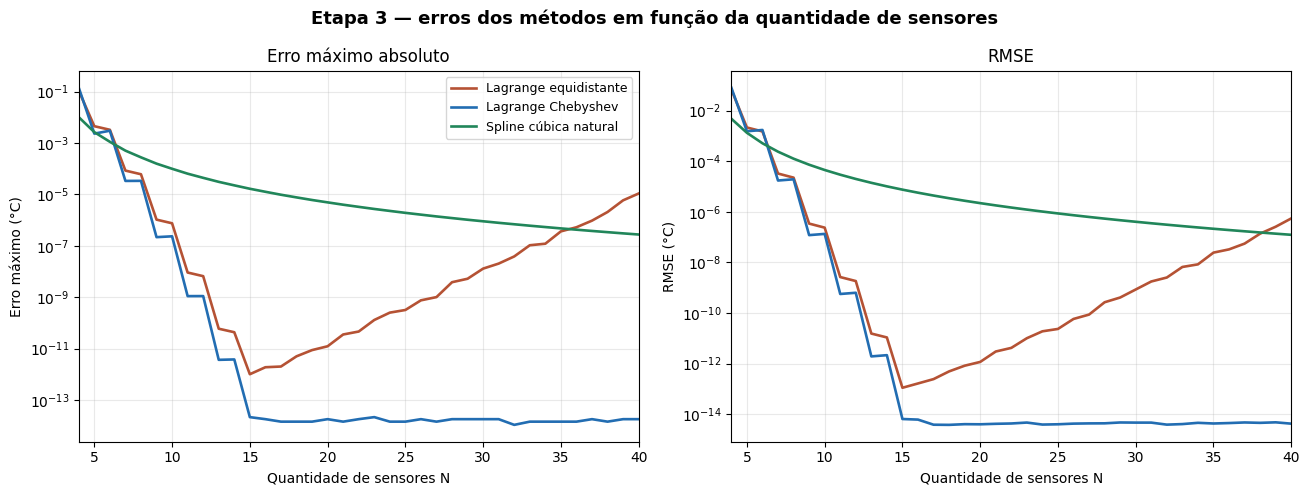

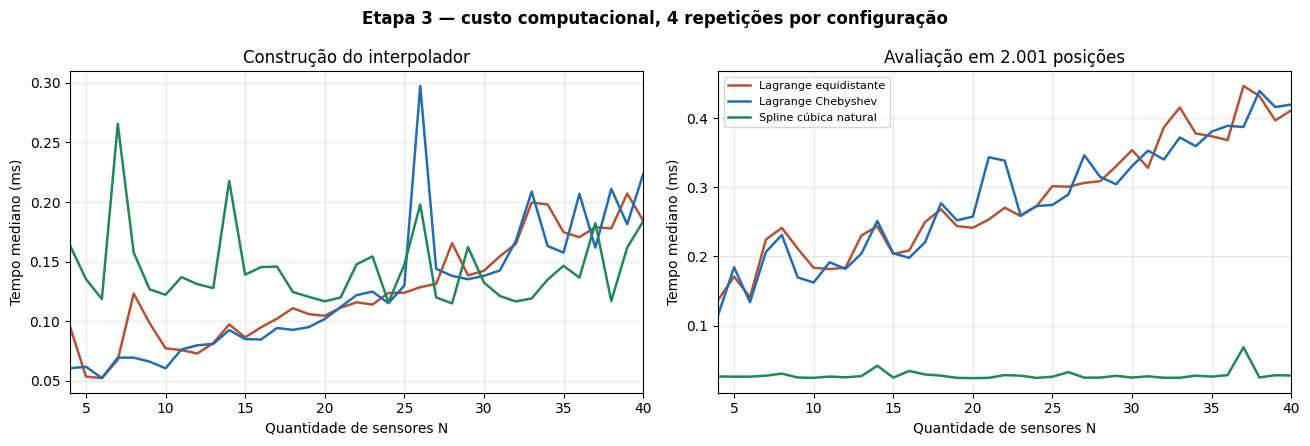

In [ ]:
# Gráficos de erro (escala logarítmica)
cores_varredura = {
    'Lagrange equidistante': '#b55234',
    'Lagrange Chebyshev': '#226db2',
    'Spline cúbica natural': '#21865a'
}
fig, eixos = plt.subplots(1, 2, figsize=(13.2, 5))
for nome, grupo in tabela_varredura.groupby('Método', sort=False):
    for ax, metrica in zip(eixos, ['Erro máximo (°C)', 'RMSE (°C)']):
        ax.semilogy(grupo['N'], np.maximum(grupo[metrica], np.finfo(float).eps),
                    label=nome, lw=1.9, color=cores_varredura[nome])
        ax.set(xlabel='Quantidade de sensores N', ylabel=metrica,
               xlim=(4, 40))
        ax.grid(alpha=.27, which='both')
eixos[0].set_title('Erro máximo absoluto')
eixos[1].set_title('RMSE')
eixos[0].legend(fontsize=9)
fig.suptitle('Etapa 3 — erros dos métodos em função da quantidade de sensores',
             fontsize=13, weight='bold')
plt.tight_layout()
plt.show()

# Tempo de construção e tempo para avaliar a malha de 2.001 pontos
fig, eixos = plt.subplots(1, 2, figsize=(13.2, 4.5))
for nome, grupo in tabela_varredura.groupby('Método', sort=False):
    for ax, coluna in zip(eixos, ['Construção (ms)', 'Avaliação (ms)']):
        ax.plot(grupo['N'], grupo[coluna], label=nome,
                lw=1.8, color=cores_varredura[nome])
        ax.set(xlabel='Quantidade de sensores N', ylabel='Tempo mediano (ms)',
               xlim=(4, 40))
        ax.grid(alpha=.28)
eixos[0].set_title('Construção do interpolador')
eixos[1].set_title('Avaliação em 2.001 posições')
eixos[1].legend(fontsize=8)
fig.suptitle('Etapa 3 — custo computacional, 4 repetições por configuração',
             fontsize=12, weight='bold')
plt.tight_layout()
plt.show()

### Análise da Etapa 3 — precisão, estabilidade e tempo

**Não existe um método invariavelmente melhor para todo $N$.** Com apenas quatro sensores, a spline cúbica natural apresenta RMSE de aproximadamente $4{,}79\times10^{-3}$ °C, enquanto Lagrange equidistante fica em cerca de $6{,}83\times10^{-2}$ °C. Já com sete sensores exatos, Lagrange obtém erro menor que a spline cúbica, conforme observado na Etapa 1.

Para valores intermediários de $N$, a suavidade do perfil permite convergência muito rápida dos polinômios globais. Entretanto, o Lagrange com nós **equidistantes** perde precisão numérica quando $N$ se torna elevado, mesmo usando a forma baricêntrica: os erros voltam a crescer em parte da faixa analisada. Os nós de Chebyshev–Lobatto são menos sensíveis a esse problema e chegam próximos do limite de arredondamento do ponto flutuante. A spline cúbica natural melhora progressivamente com mais nós, sem exigir um polinômio global de grau alto. Sua condição de segunda derivada nula nos extremos é, neste caso idealizado, compatível com o perfil analítico.

**Custo computacional:** a tabela registra separadamente o tempo para construir cada interpolador e para avaliar os 2.001 pontos de teste. Essas durações são valores *medidos*, não complexidades assintóticas, e dependem da máquina, da versão das bibliotecas e da carga do sistema. A avaliação de Lagrange envolve contribuições de todos os nós; já a spline utiliza polinômios locais em cada intervalo. Os tempos pequenos podem apresentar flutuações de medição. Erros abaixo de aproximadamente $10^{-12}$ °C não têm significado prático nesta simulação: nessa ordem predominam efeitos numéricos.

## Etapa 4 — Estudo de caso e decisão técnica

Uma equipe precisa estimar a temperatura em posições internas da barra, com sensores ruidosos. Não haverá sensores em todos os pontos e a solução verdadeira será desconhecida em campo. Com base nos experimentos, escreva uma recomendação técnica.

A recomendação deve responder:
- que método escolheria com poucos sensores exatos e por quê;
- como a recomendação muda quando se aumenta o número de sensores;
- o que faria quando os sensores apresentam ruído;
- que cuidados adotaria perto das extremidades;
- que limitações permanecem quando a temperatura verdadeira não é conhecida.

Use pelo menos duas métricas da atividade. Diferencie interpolação dentro do intervalo medido de extrapolação além dele.

### Experimento complementar — efeito de ruído nos sensores

A introdução da tarefa solicita avaliar medições perturbadas por ruído, mas não estabelece um nível de ruído nem um procedimento de simulação. Para apoiar a recomendação técnica, adotamos **como hipótese ilustrativa** um ruído gaussiano independente, de média zero e desvio padrão $\sigma=0{,}10$ °C, nas 19 medições internas de um conjunto de $N=21$ sensores. As temperaturas nas extremidades são mantidas exatas, porque representam condições prescritas do modelo. A mesma sequência de perturbações é aplicada aos nós equidistantes e de Chebyshev para permitir uma comparação controlada.

Além de três interpoladores, incluímos uma **spline cúbica suavizadora** (`UnivariateSpline`) para ilustrar a diferença entre interpolar *exatamente* cada leitura e ajustar uma curva que tolere desvios das medições. Como ela não impõe automaticamente as temperaturas nas extremidades, é um exemplo exploratório, **não uma solução de campo pronta** para este problema físico.

Etapa 4 — erro com ruído gaussiano de σ = 0,10 °C (uma realização):


,Método,Erro máximo (°C),MAE (°C),RMSE (°C)
0,Spline suavizadora (livre),1.88565e-01,4.82564e-02,6.09363e-02
1,Spline cúbica natural,2.57631e-01,7.16115e-02,9.61428e-02
2,Lagrange Chebyshev,2.71861e-01,7.62880e-02,9.67946e-02
3,Lagrange equidistante,6.64027e+02,3.78301e+01,1.29940e+02


Temperaturas previstas nas extremidades para a spline suavizadora livre: [17.8114 20.3382] °C


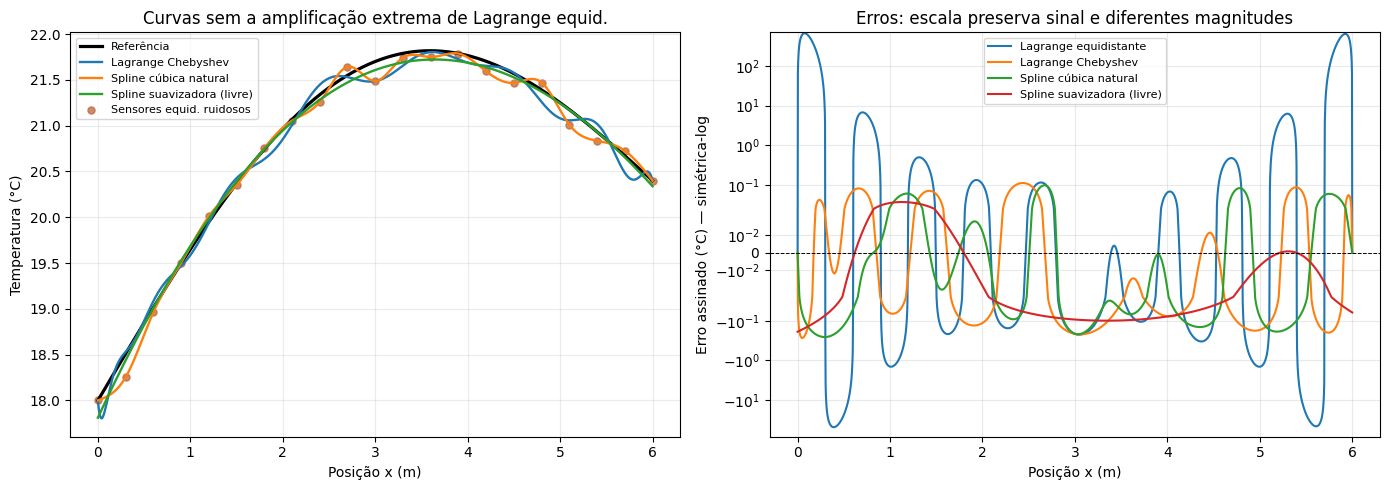

In [ ]:
# Etapa 4 — comparação reprodutível com ruído de medição
from scipy.interpolate import UnivariateSpline

N_ruido = 21
sigma_ruido = 0.10  # °C; hipótese do experimento, não informada no enunciado
x_equi_ruido = np.linspace(0, L, N_ruido)
x_cheb_ruido = nos_chebyshev_lobatto(0, L, N_ruido)

rng = np.random.default_rng(20261118)
perturbacao = np.zeros(N_ruido)
perturbacao[1:-1] = rng.normal(0, sigma_ruido, N_ruido-2)
y_equi_ruido = temperatura_real(x_equi_ruido) + perturbacao
y_cheb_ruido = temperatura_real(x_cheb_ruido) + perturbacao

def metodos_com_ruido(y_equi, y_cheb):
    return {
        'Lagrange equidistante': BarycentricInterpolator(x_equi_ruido, y_equi),
        'Lagrange Chebyshev': BarycentricInterpolator(x_cheb_ruido, y_cheb),
        'Spline cúbica natural': CubicSpline(x_equi_ruido, y_equi, bc_type='natural'),
        'Spline suavizadora (livre)': UnivariateSpline(
            x_equi_ruido, y_equi, k=3, s=(N_ruido-2)*sigma_ruido**2)
    }

modelos_ruido = metodos_com_ruido(y_equi_ruido, y_cheb_ruido)
metricas_ruido = calcular_metricas(modelos_ruido, x_fino, T_fino)
print('Etapa 4 — erro com ruído gaussiano de σ = 0,10 °C (uma realização):')
display(metricas_ruido.style.format({
    'Erro máximo (°C)': '{:.5e}', 'MAE (°C)': '{:.5e}',
    'RMSE (°C)': '{:.5e}'
}))
print('Temperaturas previstas nas extremidades para a spline suavizadora livre:',
      np.round(modelos_ruido['Spline suavizadora (livre)']([0, L]), 5), '°C')

# (a) Curvas dentro da escala física; (b) erros assinados com escala simétrica-log.
# A escala simétrica-log revela simultaneamente o erro enorme do polinômio
# equidistante e os erros pequenos dos demais métodos.
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.plot(x_fino, T_fino, color='black', lw=2.3, label='Referência')
for nome in ['Lagrange Chebyshev', 'Spline cúbica natural', 'Spline suavizadora (livre)']:
    ax1.plot(x_fino, modelos_ruido[nome](x_fino), lw=1.7, label=nome)
ax1.scatter(x_equi_ruido, y_equi_ruido, s=26, color='#bc663a',
            alpha=.75, label='Sensores equid. ruidosos')
ax1.set(xlabel='Posição x (m)', ylabel='Temperatura (°C)',
        title='Curvas sem a amplificação extrema de Lagrange equid.')
ax1.legend(fontsize=8)
ax1.grid(alpha=.25)

for nome, modelo in modelos_ruido.items():
    ax2.plot(x_fino, np.asarray(modelo(x_fino))-T_fino, label=nome, lw=1.5)
ax2.axhline(0, ls='--', color='black', lw=.7)
ax2.set_yscale('symlog', linthresh=0.025)
ax2.set(xlabel='Posição x (m)', ylabel='Erro assinado (°C) — simétrica-log',
        title='Erros: escala preserva sinal e diferentes magnitudes')
ax2.grid(alpha=.28, which='both')
ax2.legend(fontsize=8, loc='upper center')
plt.tight_layout()
plt.show()

In [ ]:
# Repetição do experimento com vários conjuntos de ruídos: avaliação de robustez
# As estatísticas abaixo descrevem o erro frente ao perfil conhecido nesta simulação.
rng_mc = np.random.default_rng(20261119)
repeticoes_mc = 60
linhas_mc = []
for repeticao in range(repeticoes_mc):
    ruido = np.zeros(N_ruido)
    ruido[1:-1] = rng_mc.normal(0, sigma_ruido, N_ruido-2)
    y_equi = temperatura_real(x_equi_ruido) + ruido
    y_cheb = temperatura_real(x_cheb_ruido) + ruido
    for nome, modelo in metodos_com_ruido(y_equi, y_cheb).items():
        erro = np.asarray(modelo(x_fino)) - T_fino
        linhas_mc.append({
            'Repetição': repeticao + 1, 'Método': nome,
            'RMSE (°C)': np.sqrt(np.mean(erro**2)),
            'Erro máximo (°C)': np.max(np.abs(erro))
        })

ensaios_mc = pd.DataFrame(linhas_mc)
resumo_ruido = (ensaios_mc.groupby('Método')
                .agg(RMSE_mediano=('RMSE (°C)', 'median'),
                     RMSE_p90=('RMSE (°C)', lambda serie: serie.quantile(.9)),
                     Emax_mediano=('Erro máximo (°C)', 'median'))
                .reset_index().sort_values('RMSE_mediano'))
print(f'Etapa 4 — robustez em {repeticoes_mc} realizações independentes do ruído:')
display(resumo_ruido.style.format({
    'RMSE_mediano': '{:.5e}', 'RMSE_p90': '{:.5e}',
    'Emax_mediano': '{:.5e}'
}))

Etapa 4 — robustez em 60 realizações independentes do ruído:


,Método,RMSE_mediano,RMSE_p90,Emax_mediano
3,Spline suavizadora (livre),5.55662e-02,7.48903e-02,1.10340e-01
2,Spline cúbica natural,8.96402e-02,1.10430e-01,2.15332e-01
0,Lagrange Chebyshev,9.84455e-02,1.21075e-01,2.29275e-01
1,Lagrange equidistante,4.42826e+01,1.30930e+02,2.66552e+02


### Recomendação técnica final

**1. Poucos sensores exatos.** A escolha depende do número de sensores e do formato esperado da temperatura. Com os **sete sensores** da Etapa 1, escolheria **Lagrange global**, pois apresentou os menores valores de erro máximo ($8{,}47\times10^{-5}$ °C) e RMSE ($3{,}27\times10^{-5}$ °C). A decisão não deve ser generalizada: com apenas **quatro sensores**, a **spline cúbica natural** alcançou RMSE menor do que os dois Lagranges na Etapa 3.

**2. Quando a quantidade de sensores aumenta.** Evitaria aumentar indefinidamente o grau de um polinômio global com **nós equidistantes**. Na Etapa 3, esse método inicialmente convergiu, mas voltou a perder precisão para valores elevados de $N$ por sensibilidade numérica. Se o posicionamento puder ser planejado e as leituras forem confiáveis, **Lagrange em nós de Chebyshev–Lobatto** é uma alternativa precisa para o perfil suave considerado. Para uso prático com sensores numerosos, daria preferência à **spline cúbica**, que utiliza polinômios locais e não depende de um único ajuste global de alto grau. Compararia também o custo de avaliação e as restrições físicas antes de decidir.

**3. Quando há ruído de medição.** Os métodos interpoladores exatos reproduzem o ruído nos nós. Na simulação adicional com $N=21$ e $\sigma=0{,}10$ °C, Lagrange equidistante teve **RMSE aproximadamente 130 °C em uma realização**, mostrando amplificação extrema do ruído, sobretudo perto das extremidades; as alternativas com Chebyshev e spline cúbica ficaram na ordem de $10^{-1}$ °C. As 60 repetições confirmam a vulnerabilidade, que não depende de uma única amostra aleatória. A spline suavizadora reduziu o RMSE no experimento, mas **não garante as temperaturas prescritas nas extremidades**: antes de utilizá-la em campo, seria necessário incorporar as condições de contorno na formulação de suavização. Recomenda-se ainda verificar calibração, repetir medições e estimar a intensidade do ruído (por exemplo, usando leituras repetidas).

**4. Cuidados nas extremidades.** Usaria as temperaturas prescritas $T(0)=18$ °C e $T(6)=20{,}4$ °C como restrições quando conhecidas; conferiria a presença de sensores nas bordas e inspecionaria a curvatura e os erros próximos a $x=0$ e $x=L$. Nós concentrados nas extremidades podem reduzir a sensibilidade de polinômios globais. Uma spline natural assume segunda derivada nula nos extremos: essa condição funciona particularmente bem para o perfil adotado, mas não deve ser aplicada automaticamente a qualquer barra real.

**5. Limitações quando a solução verdadeira é desconhecida.** As métricas **$E_{max}$, MAE e RMSE em relação a $T(x)$** só puderam ser calculadas porque a tarefa fornece uma função de referência. Em campo, sem uma curva verdadeira, essas métricas não são diretamente observáveis. Seria necessário avaliar resíduos, usar sensores independentes ou validação cruzada, considerar repetibilidade, incerteza e plausibilidade física da temperatura reconstruída. Também não se pode concluir que a vantagem de um método se mantenha para perfis com descontinuidades, aquecimento localizado ou outros níveis de ruído.

**6. Interpolação versus extrapolação.** Todas as comparações realizadas tratam de **interpolação dentro de $0\le x\le6$ m**, intervalo delimitado pelos sensores extremos. Estimar temperaturas em $x<0$ ou $x>6$ m seria **extrapolação**, situação na qual o erro pode aumentar rapidamente e as métricas calculadas neste notebook não validam a previsão. A extrapolação só seria justificável com hipóteses físicas adicionais e validação específica.

**Síntese da decisão:** para o caso idealizado com sete leituras exatas, Lagrange global tem a maior precisão. Para muitas medições reais, especialmente ruidosas, priorizaria uma **abordagem local ou de suavização com as condições de contorno explicitamente respeitadas**, em vez de interpolar todos os valores com um único polinômio de grau elevado. Esta decisão deve ser revista com dados experimentais independentes.

---
**Conclusão da atividade.** Foram concluídas as quatro etapas solicitadas, incluindo as três métricas, a análise da distribuição e da quantidade de sensores, a comparação de precisão e tempos, e a recomendação técnica. O ensaio com ruído foi acrescentado para investigar a questão proposta na introdução. Todos os experimentos usam o perfil analítico fornecido, NumPy, pandas, Matplotlib e SciPy, com sementes explícitas para o ruído.